# סיווג משלחי יד | מבחן מדען נתונים — V3
### בקרת Metadata · ייצוג TF-IDF בתקן L2 · בחירת K לפי CH · קידוד אשכולות נומינלי

**יסודות שנשמרו מ-V2:** הגיליון `Metadata` מגדיר את חוזה הנתונים. לכל עמודה המנגנון קורא את `פורמט` (`INTEGER`, `TEXT`, `DATE`), מפעיל בדיקות אוטומטיות מתאימות, ובודק קודים ויחסים נוספים **רק כאשר המקור מגדיר אותם**. כל 18 העמודות נבדקות; אין טבלת הגדרות שהועתקה ידנית ואין יצירת ערכי קטגוריות שאינם קיימים במקור.

**מטרת המטלה:** לחזות `SemelMishlachSofi` על נתוני דמה שהוכנו למבחן, ולהציג קוד, תוצאות חיזוי, איכות נתונים, הסבר פתרון ותהליך הטמעה. תוויות הסמלנים אינן אמת-מידה בלתי תלויה, ויש כ-10% שגיאות בתהליך הידני לפי תיאור המטלה. **אין לפרש את המדדים המוצגים כאומדן דיוק של מערכת ייצור.**

**עקרון ההפרדה:** (1) *בדיקת מקור* על העמודות הגולמיות; (2) *מיפוי מדויק של מגבלות המקור*; (3) *מדיניות מידול מקצועית* המוצהרת בנפרד; (4) *אימון ואימות ללא זליגת נתוני בדיקה*.

הנתונים נטענים ישירות [מקובץ Excel ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx). ניתן לפתוח את [V3 ב-Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification_v3.ipynb). אין צורך ב-SSH, במפתח גישה, בחיבור Drive או בהטמעת נתוני הסקר בקוד.

**גרסאות שמורות ללא שינוי:** V1 ו-V2 נשארות כפי שהן. מחברת V3 בוחנת הוספת אשכולות לטקסט כמועמדים לקטגוריות נומינליות, ביחס לבסיס TF-IDF הקיים. אין להניח ש-Calinski–Harabasz מודד סמנטיקה או מבטיח שיפור ניבוי.

**בדיקת רגישות נוספת:** `norm="l2"` מפורש בשתי חלופות `smooth_idf=True/False`. כל תוצאה נמדדת על אותן קבוצות; אין לבחור מודל לפריסה לפי ניסוי holdout יחיד. נציג Macro-F1, Macro-Recall ו-Weighted-F1 לצד Accuracy, משום שהמחלקות אינן מאוזנות.


## 1. תלות בסביבה ועקיבות
תא הטעינה משתמש בהורדה אנונימית של קובץ ה-Excel הציבורי מ-GitHub, וכולל SHA-256 של גרסת המקור. לצורך בדיקת הרצה מקומית בלבד אפשר להגדיר `CBS_OCCUPATION_WORKBOOK_PATH` לקובץ זהה בבייטים. ב-Colab אין צורך להגדיר דבר.

In [1]:
from __future__ import annotations
import hashlib
import io
import os
import re
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
# Colors sampled from the portfolio's saved homepage screenshot, not claimed as live CSS.
PALETTE = {"blue": "#356343", "teal": "#789A79", "gray": "#657362",
           "pale": "#E3E9DE", "orange": "#9D8E63", "edge": "#304C38"}
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 65)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.8.0


## 2. טעינת שני הגיליונות לפי המבנה המקורי
קוראים תחילה את ארבע עמודות ההגדרה של `Metadata`, משום שבקובץ המקורי קיימת התפרסות עיצובית של הגיליון אל מעבר לשדות המידע. אחר כך משתמשים בטיפוסי המקור כדי לטעון במפורש את שדות `TEXT` כמחרוזות. קוד `123` נשאר `"123"` ואינו מושלם אוטומטית לארבע ספרות. שורת הסיכום היחידה ללא `ID` אינה משתתף ולכן מוצאת רק *ממערך הניתוח*, בלי לשנות את הקובץ המקורי.

In [2]:
SOURCE_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
EXPECTED_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
local_test_path = os.environ.get("CBS_OCCUPATION_WORKBOOK_PATH")
if local_test_path:
    excel_bytes = Path(local_test_path).read_bytes()
else:
    req = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "occupation-analysis-v3"})
    with urllib.request.urlopen(req, timeout=60) as response:
        excel_bytes = response.read()
actual_hash = hashlib.sha256(excel_bytes).hexdigest()
assert actual_hash == EXPECTED_SHA256, (
    "Dataset version changed. Inspect Metadata and source rows before reporting results."
)
file = pd.ExcelFile(io.BytesIO(excel_bytes), engine="openpyxl")
assert set(file.sheet_names) == {"Survey Dataset", "Metadata"}
metadata = pd.read_excel(file, sheet_name="Metadata", usecols="A:D", dtype="string")
metadata.columns = metadata.columns.astype(str).str.strip()
meta_fields = ["משתנה", "הסבר", "פורמט", "ערכים אפשריים"]
assert metadata.columns.tolist() == meta_fields
metadata = metadata.loc[metadata["משתנה"].notna(), meta_fields].copy()
for c in ["משתנה", "פורמט"]:
    metadata[c] = metadata[c].str.strip()
assert metadata["משתנה"].is_unique
assert metadata["פורמט"].isin(["INTEGER", "TEXT", "DATE"]).all()
text_columns = metadata.loc[metadata["פורמט"].eq("TEXT"), "משתנה"].tolist()
raw_survey = pd.read_excel(file, sheet_name="Survey Dataset",
                           dtype={field: "string" for field in text_columns})
non_participant = raw_survey.loc[raw_survey["ID"].isna()].copy()
survey = raw_survey.loc[raw_survey["ID"].notna()].copy().reset_index(drop=True)
assert survey.shape == (200, 18)
assert metadata.shape == (18, 4)
assert set(survey.columns) == set(metadata["משתנה"])
assert len(non_participant) == 1
print("Workbook SHA-256:", actual_hash)
print("Survey records:", len(survey), "| Columns:", len(survey.columns),
      "| Metadata definitions:", len(metadata), "| Non-participant summary rows:", len(non_participant))
display(survey[["ID", "EzoAvoda", "SemelMishlachSofi"]].head(5))

Workbook SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Survey records: 200 | Columns: 18 | Metadata definitions: 18 | Non-participant summary rows: 1


,ID,EzoAvoda,SemelMishlachSofi
0,1.0,סגן מנהל אגף,2120
1,2.0,טכנאית רדיותרפיה,3311
2,3.0,נותנת תמיכה ללקוחות שמבקשים עזרה,3512
3,4.0,שומר בבית הספר,5414
4,5.0,מטפל בקשיש,5322


## 3. הפיכת ה-Metadata עצמו לחוזה בדיקות
המנגנון הבא **אינו מעתיק את ההגדרות**: הוא קורא את כל שורות `metadata` ומחלץ רק כללים שהטקסט מספק בפועל.

- `פורמט` קובע אילו בדיקות טיפוס מופעלות בכל עמודה.
- רשימות ממוספרות בגוף `ערכים אפשריים` מפעילות בדיקת תחום עבור הקודים המפורטים בלבד.
- הביטוי "מורכב מ-4 ספרות" מפעיל בדיקת מבנה קוד של ארבעה תווים.
- הכיתוב "משתנה המטרה" מזהה את עמודת היעד.

**הגבלה אפיסטמית:** הטיפוס אינו קובע לבדו היעדר חסרים, מינימום גיל, סדר אורדינלי או הרשאה להשתמש בשדה לחיזוי. מידע כזה דורש הגדרה נפרדת. נתון חסר אינו נחשב אוטומטית לשגיאה, כי המטלה מאפשרת שאלון חלקי.

In [3]:
def parse_enumerated_codes(raw):
    """Codes are extracted only from numbered lines explicitly supplied by Metadata."""
    if pd.isna(raw):
        return {}
    pairs = re.findall(r"(?m)^\s*(\d+)\.\s*(\S[^\n]*?)\s*$", str(raw))
    return {int(number): label.strip() for number, label in pairs}

def code_width_from_description(description):
    if pd.isna(description):
        return None
    match = re.search(r"מורכב\s*מ\s*[-־]?\s*(\d+)\s*ספרות", str(description))
    return int(match.group(1)) if match else None

contracts = metadata.set_index("משתנה", verify_integrity=True)
enumerations = {field: parse_enumerated_codes(contracts.loc[field, "ערכים אפשריים"])
                for field in survey.columns}
widths = {field: code_width_from_description(contracts.loc[field, "הסבר"])
          for field in survey.columns}
identified_targets = metadata.loc[
    metadata["ערכים אפשריים"].fillna("").str.contains("משתנה המטרה", regex=False), "משתנה"
].tolist()
assert identified_targets == ["SemelMishlachSofi"]
TARGET = identified_targets[0]
assert widths["SemelAnafSofi"] == widths[TARGET] == 4
print("Metadata type counts:", contracts["פורמט"].value_counts().to_dict())
print("Enumerations specified in source:", {k:len(v) for k,v in enumerations.items() if v})
print("Four-digit code fields:", [k for k,v in widths.items() if v==4])
for row_start in range(0,len(metadata),4):
    print(f"Metadata definitions {row_start+1}–{min(row_start+4,len(metadata))}")
    display(metadata.iloc[row_start:row_start+4][["משתנה","פורמט","הסבר"]].reset_index(drop=True))

Metadata type counts: {'TEXT': 10, 'INTEGER': 7, 'DATE': 1}
Enumerations specified in source: {'MenahelEtMi': 3, 'MaamadAvoda': 7, 'MakorSachar': 4, 'TeudaGvoha': 9}
Four-digit code fields: ['SemelAnafSofi', 'SemelMishlachSofi']
Metadata definitions 1–4


,משתנה,פורמט,הסבר
0,ID,INTEGER,מספר רץ
1,YeshuvAvoda,TEXT,שם יישוב עבודה
2,ShemAvoda,TEXT,שם מקום העבודה שלך
3,SugAvoda,TEXT,הפעילות העיקרית של מקום העבודה


Metadata definitions 5–8


,משתנה,פורמט,הסבר
0,ShemMachlaka,TEXT,אגף או מחלקה שהנסקר עובד
1,SugMachlaka,TEXT,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד
2,EzoAvoda,TEXT,עבודה שהנסקר עושה במקום עבודה זה
3,TeurPeula,TEXT,הפעולות העיקריות שהנסקר עושה במקום עבודה


Metadata definitions 9–12


,משתנה,פורמט,הסבר
0,TeurTafkid,TEXT,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש)
1,MenahelEtMi,INTEGER,האם הנסקר מנהל או ממונה על עובדים אחרים?
2,MaamadAvoda,INTEGER,מעמד הנסקר במקום עבודה זה
3,MakorSachar,INTEGER,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר שכיר או חבר קואו...


Metadata definitions 13–16


,משתנה,פורמט,הסבר
0,TeudaGvoha,INTEGER,התעודה או התואר הגבוה ביותר של הנסקר
1,shnotlimud,INTEGER,שנות הלימוד של הנסקר
2,Gil,INTEGER,גיל הנסקר
3,SemelAnafSofi,TEXT,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספרות לפי תקן בינלאומי


Metadata definitions 17–18


,משתנה,פורמט,הסבר
0,TarichHathala,DATE,תאריך התחלת התפקיד
1,SemelMishlachSofi,TEXT,סמל משלח יד - מורכב מ-4 ספרות לפי תקן בינלאומי


## 4. מנוע הבדיקות: טיפוס השדה מפעיל את הבדיקות
`validate_type()` הוא פונקציית ניתוב לפי `פורמט`, שאינה מכילה רשימה ידנית של 18 תיאורי עמודות. כל תוצאה היא מסכת שורות המשויכת לשדה ולכלל המקור. הודעות חריגה אינן מוחקות ערכים ואינן מבצעות המרות שקטות.

**`INTEGER`:** זיהוי ערכים שאינם מספרים, שברים שאינם מספרים שלמים, והפרת רשימה ממוספרת אם קיימת במטא-דאטה. **`TEXT`:** טיפול באחסון כמחרוזת ובדיקת רוחב לקודים רק כאשר הוא מוצהר. **`DATE`:** זיהוי תאריכים שאי אפשר לפענח. לכל טיפוס נרשמים חסרים, שכיחויות ושונות כמדדי תיאור, ללא הנחת חובה למלא.

In [4]:
def occupied(series):
    return series.notna() & series.astype("string").str.strip().fillna("").ne("")

def validate_type(frame, field):
    """Return row-level masks. Source values are never changed."""
    kind = str(contracts.loc[field, "פורמט"])
    series = frame[field]
    nonempty = occupied(series)
    flags = {}
    if kind == "INTEGER":
        numeric = pd.to_numeric(series, errors="coerce")
        flags["non_numeric"] = nonempty & numeric.isna()
        flags["non_integral"] = (numeric.notna() & numeric.mod(1).ne(0)).fillna(False)
        if enumerations[field]:
            flags["outside_enumeration"] = (
                numeric.notna() & ~numeric.isin(enumerations[field])
            ).fillna(False)
    elif kind == "TEXT":
        if widths[field] is not None:
            text = series.astype("string").str.strip()
            pattern = rf"[0-9Xx]{{{widths[field]}}}"
            flags["code_shape_mismatch"] = (
                nonempty & ~text.str.fullmatch(pattern, na=False)
            ).fillna(False)
            flags["partial_X_code"] = (
                nonempty & text.str.fullmatch(pattern, na=False)
                & text.str.contains("X",case=False,regex=False,na=False)
            ).fillna(False)
    elif kind == "DATE":
        parsed = pd.to_datetime(series,errors="coerce",format="mixed")
        flags["unparseable_date"] = nonempty & parsed.isna()
    else:
        raise ValueError(f"Metadata type {kind!r} is unsupported; no silent fallback")
    return {rule: mask.astype(bool) for rule,mask in flags.items()}

source_issues = []
summary_rows = []
checklist_rows = []
for field in survey.columns:
    flags = validate_type(survey, field)
    is_present = occupied(survey[field])
    checks = ["presence", "type:"+contracts.loc[field,"פורמט"]]
    if enumerations[field]: checks.append("declared_domain")
    if widths[field]: checks.append("declared_code_width")
    for rule, mask in flags.items():
        if not mask.any() or rule=="partial_X_code": continue  # A partial code is a review status, not a type-contract violation.
        for idx in survey.index[mask]:
            source_issues.append({"ID": survey.loc[idx,"ID"], "field":field,
                                  "rule":rule, "original":str(survey.loc[idx,field]),
                                  "provenance":"Metadata: "+str(contracts.loc[field,"פורמט"])})
    populated = survey.loc[is_present,field].astype("string").str.strip()
    summary_rows.append({"field":field, "type":str(contracts.loc[field,"פורמט"]),
                         "missing":int((~is_present).sum()),
                         "missing_pct":round(float((~is_present).mean()*100),1),
                         "distinct_nonmissing":int(populated.nunique()),
                         "checks":", ".join(checks),
                         "violations":sum(int(mask.sum()) for rule,mask in flags.items()
                                          if rule!="partial_X_code"),
                         "X_partial":int(flags.get("partial_X_code",pd.Series(False,index=survey.index)).sum())})
    checklist_rows.append({"field":field,
        "presence":True,
        "integer":contracts.loc[field,"פורמט"]=="INTEGER",
        "text":contracts.loc[field,"פורמט"]=="TEXT",
        "date":contracts.loc[field,"פורמט"]=="DATE",
        "enumeration":bool(enumerations[field]),
        "code_width":widths[field] is not None})
summary=pd.DataFrame(summary_rows)
issues=pd.DataFrame(source_issues,columns=["ID","field","rule","original","provenance"])
checklist=pd.DataFrame(checklist_rows).set_index("field")
assert len(summary)==18 and checklist.shape==(18,6)
for start in range(0,len(summary),6):
    display(summary.iloc[start:start+6][["field","type","missing","missing_pct","violations","X_partial"]])
print("Source violations (excluding valid partial X labels):",len(issues))
print("Validation issues by rule:")
display(issues.groupby(["rule","field"]).size().rename("records").reset_index() if len(issues)
        else pd.DataFrame({"status":["No type-validation violations"]}))

,field,type,missing,missing_pct,violations,X_partial
0,ID,INTEGER,0,0.0,0,0
1,YeshuvAvoda,TEXT,0,0.0,0,0
2,ShemAvoda,TEXT,0,0.0,0,0
3,SugAvoda,TEXT,25,12.5,0,0
4,ShemMachlaka,TEXT,64,32.0,0,0
5,SugMachlaka,TEXT,134,67.0,0,0


,field,type,missing,missing_pct,violations,X_partial
6,EzoAvoda,TEXT,7,3.5,0,0
7,TeurPeula,TEXT,136,68.0,0,0
8,TeurTafkid,TEXT,172,86.0,0,0
9,MenahelEtMi,INTEGER,168,84.0,0,0
10,MaamadAvoda,INTEGER,2,1.0,0,0
11,MakorSachar,INTEGER,14,7.0,0,0


,field,type,missing,missing_pct,violations,X_partial
12,TeudaGvoha,INTEGER,2,1.0,0,0
13,shnotlimud,INTEGER,2,1.0,0,0
14,Gil,INTEGER,2,1.0,0,0
15,TarichHathala,DATE,0,0.0,0,0
16,SemelAnafSofi,TEXT,0,0.0,5,9
17,SemelMishlachSofi,TEXT,0,0.0,0,9


Source violations (excluding valid partial X labels): 5
Validation issues by rule:


,rule,field,records
0,code_shape_mismatch,SemelAnafSofi,5


## 5. בדיקות יחידה למנגנון — הוכחה שהכללים אכן מופעלים
לפני שימוש עסקי, משנים **עותק בדיקה זמני בלבד** ומוכיחים שהמנגנון מגלה קלט לא תקין. הבדיקות בוחנות את הטיפוס, תחום הקודים והמבנה המוגדר במקור. שום שינוי אינו נשמר בקובץ הסקר.

In [5]:
def assert_detected(field, invalid, expected_rule):
    sample = survey[[field]].astype({field: "object"}).copy()
    sample.loc[0,field] = invalid
    observed = validate_type(sample,field)
    assert expected_rule in observed, (field,expected_rule)
    assert observed[expected_rule].iloc[0], (field,invalid,expected_rule)

assert_detected("shnotlimud", "not-an-integer", "non_numeric")
assert_detected("Gil", 31.5, "non_integral")
assert_detected("MaamadAvoda", 99, "outside_enumeration")
assert_detected("TarichHathala", "not-a-date", "unparseable_date")
assert_detected("SemelAnafSofi", "12", "code_shape_mismatch")
assert_detected("SemelMishlachSofi", "1X3X", "partial_X_code")
assert sum(int(m.sum()) for rule,m in validate_type(survey,"EzoAvoda").items())==0
print("6 mutated-input tests and 1 source-text control: PASSED")

6 mutated-input tests and 1 source-text control: PASSED


## 6. הפעלת בדיקות רוחב על כל השדות — תצוגה גרפית
מטריצת הפעלה מסבירה בדיוק מה מופעל אוטומטית עבור כל שדה. התרשימים נגזרים מן הטיפוסים והקודים שנמצאו ב-Metadata המקורי; הם אינם נתונים מיוצרים ואינם תחומי ערכים משוערים.

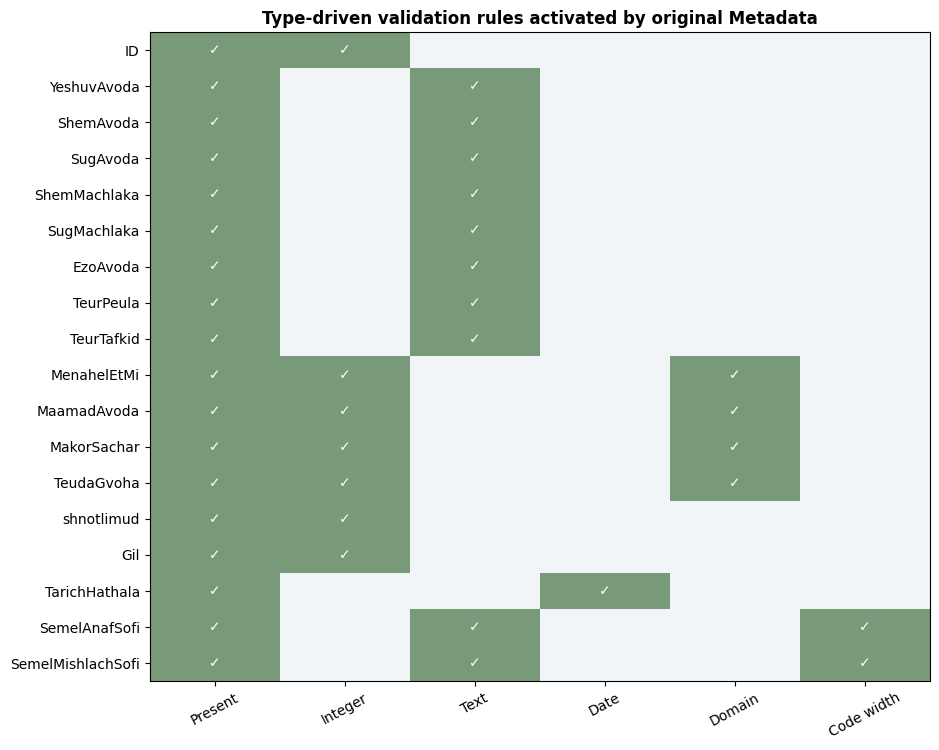

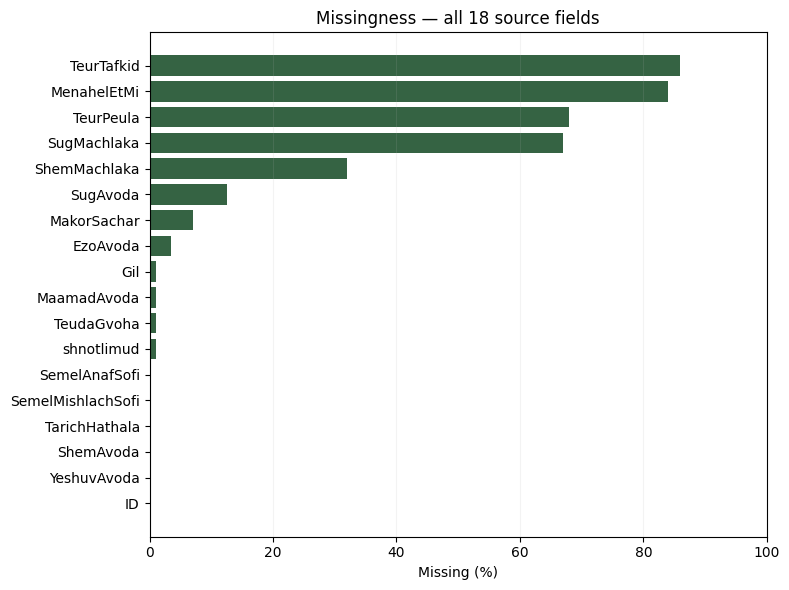

In [6]:
fig, ax = plt.subplots(figsize=(9.5,7.6))
ax.imshow(checklist.astype(int).values, aspect="auto",
          cmap=ListedColormap(["#F1F5F7",PALETTE["teal"]]), vmin=0,vmax=1)
ax.set_yticks(range(len(checklist.index)),labels=checklist.index)
ax.set_xticks(range(len(checklist.columns)),labels=["Present","Integer","Text","Date","Domain","Code width"])
ax.tick_params(axis='x', labelrotation=28)
for y in range(len(checklist.index)):
    for x in range(len(checklist.columns)):
        if checklist.iat[y,x]: ax.text(x,y,"✓",va="center",ha="center",color="white",fontsize=10)
ax.set_title("Type-driven validation rules activated by original Metadata",fontweight="bold")
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,6.0))
ordered=summary.sort_values("missing_pct")
ax.barh(ordered["field"],ordered["missing_pct"],color=PALETTE["blue"])
ax.set(xlabel="Missing (%)",title="Missingness — all 18 source fields",xlim=(0,100))
ax.grid(axis="x",alpha=.15)
fig.tight_layout();plt.show()

## 7. תרשים מותאם-טיפוס לכל אחד מ-18 השדות
פונקציית השרטוט עצמה קוראת את הטיפוס והערכים מהמקור. `INTEGER` עם ערכים מקודדים מוצג כקטגוריות, `INTEGER` חופשי כהיסטוגרמה, `DATE` לפי שנה, `TEXT` לפי שכיחויות. אין להמיר את קודי ההשכלה לסולם מספרי רק משום שפורמט השדה הוא `INTEGER`. תוויות עבריות ארוכות מוצגות בטבלת הסבר נפרדת כדי למנוע טקסט קטוע ב-Colab בנייד.

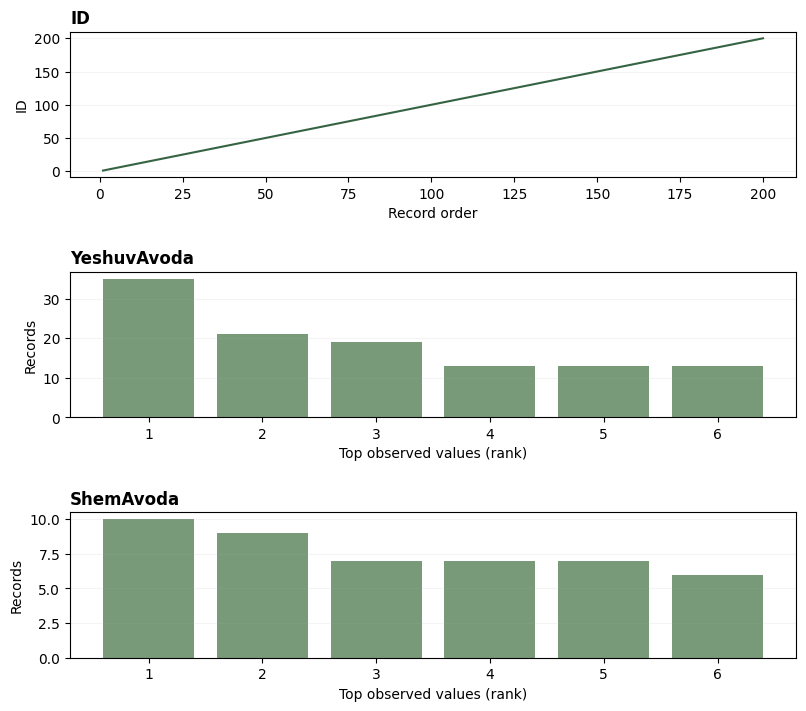

YeshuvAvoda: top observed source text: תל אביב (35) | ירושלים (21) | חיפה (19)
ShemAvoda: top observed source text: מסעדה (10) | משרד החינוך (9) | בנק לאומי (7)


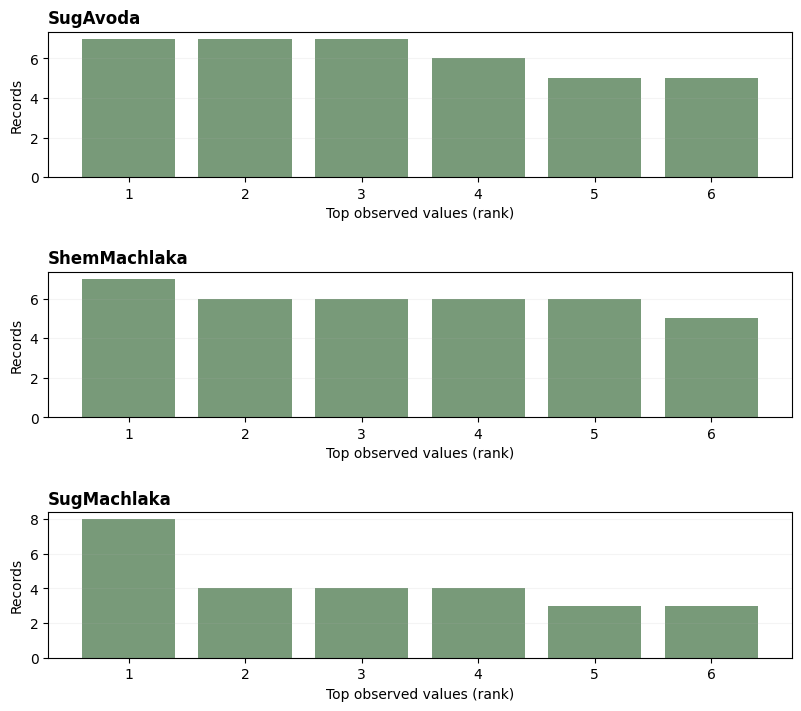

SugAvoda: top observed source text: בית ספר יסודי (7) | מסעדה (7) | חנות למכירת בגדים (7)
ShemMachlaka: top observed source text: שמירה (7) | תמיכה בלקוחות (6) | קוסמטיקה וטיפוח (6)
SugMachlaka: top observed source text: כנ"ל (8) | טיפול בחולי סרטן (4) | טיפול באנשים עם בעיות (4)


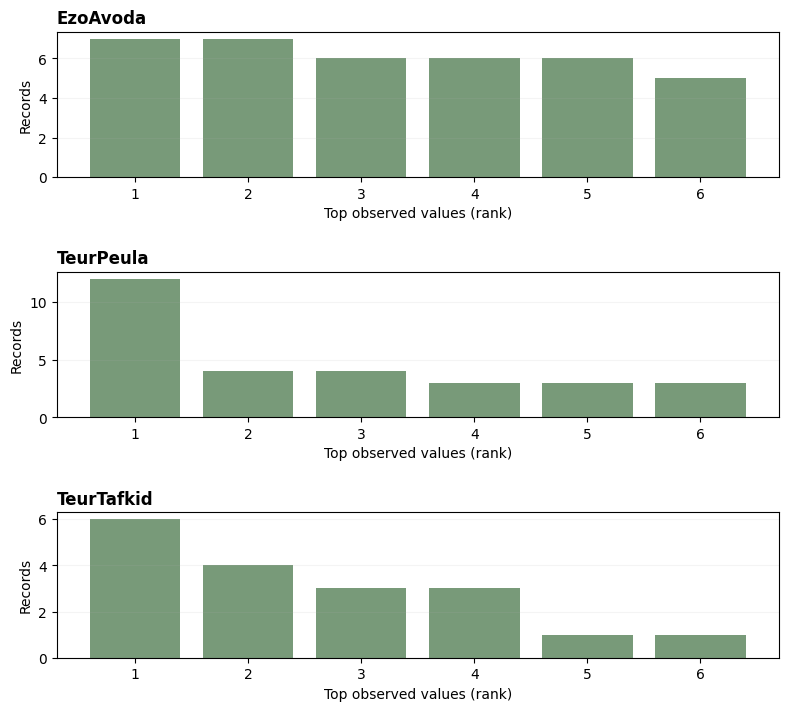

EzoAvoda: top observed source text: שומר בבית הספר (7) | טבח (7) | מנקה בית ספר אחרי הלימודים (6)
TeurPeula: top observed source text: כנ"ל (12) | מפקח על תהליך ייצור צ'יפים (4) | מסבירה לאנשים לגבי מוצרים של חברת LOREAL (4)
TeurTafkid: top observed source text: כלכלן (6) | כנ"ל (4) | סגן מנהל אגף (3)


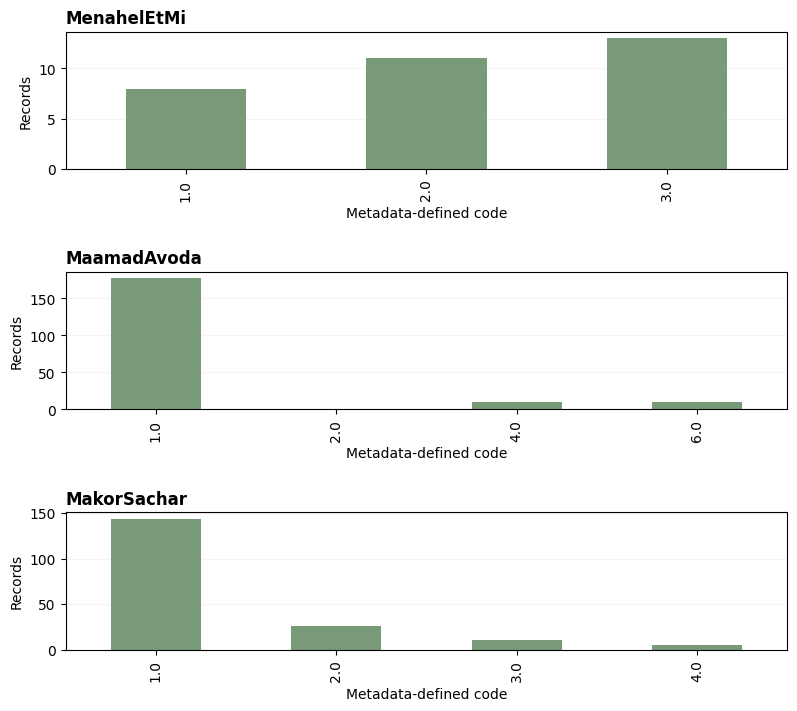

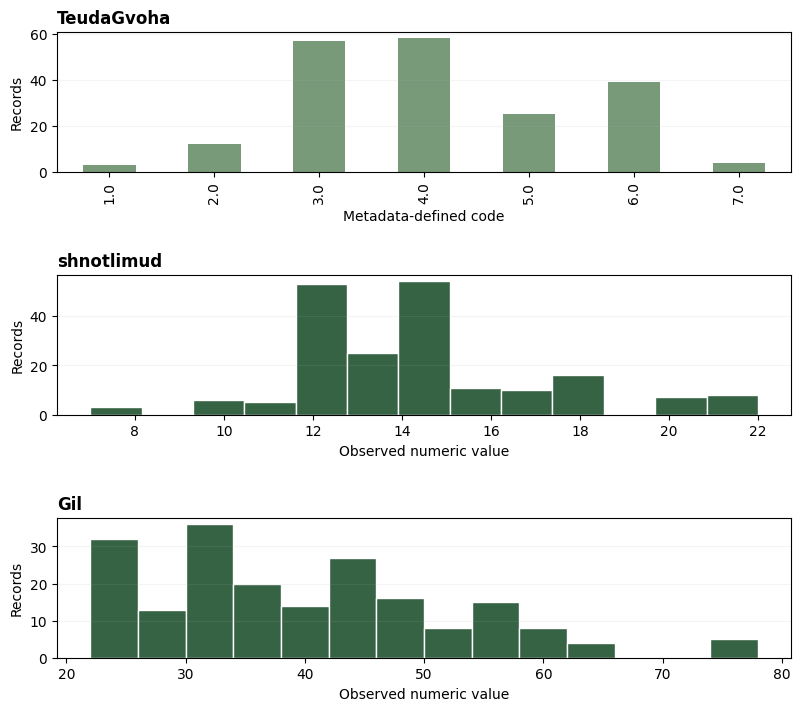

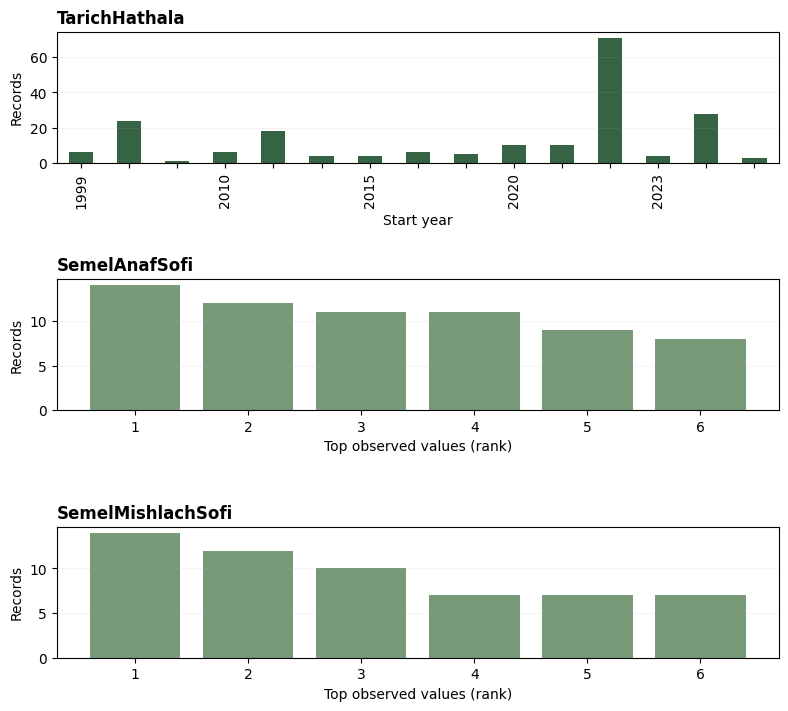

SemelAnafSofi: top observed source text: 5610 (14) | 6201 (12) | 8411 (11)
SemelMishlachSofi: top observed source text: 5223 (14) | 9112 (12) | 2512 (10)


In [7]:
def plot_from_type(field,ax):
    kind=contracts.loc[field,"פורמט"]
    s=survey[field]
    if kind=="DATE":
        yearly=pd.to_datetime(s,errors="coerce",format="mixed").dt.year.value_counts().sort_index()
        yearly.plot.bar(ax=ax,color=PALETTE["blue"])
        ax.set(xlabel="Start year",ylabel="Records")
        for n,item in enumerate(ax.get_xticklabels()):
            if n%3: item.set_visible(False)
    elif kind=="INTEGER" and enumerations[field]:
        counts=pd.to_numeric(s,errors="coerce").value_counts().sort_index()
        counts.plot.bar(ax=ax,color=PALETTE["teal"])
        ax.set(xlabel="Metadata-defined code",ylabel="Records")
    elif kind=="INTEGER" and field!="ID":
        nums=pd.to_numeric(s,errors="coerce").dropna()
        ax.hist(nums,bins=min(14,max(2,nums.nunique())),color=PALETTE["blue"],edgecolor="white")
        ax.set(xlabel="Observed numeric value",ylabel="Records")
    elif field=="ID":
        ax.plot(range(1,len(s)+1),pd.to_numeric(s),color=PALETTE["blue"])
        ax.set(xlabel="Record order",ylabel="ID")
    else:
        cleaned=s.astype("string").str.strip().replace("",pd.NA)
        counts=cleaned.value_counts().head(6)
        ax.bar(range(1,len(counts)+1),counts.values,color=PALETTE["teal"])
        ax.set_xticks(range(1,len(counts)+1))
        ax.set(xlabel="Top observed values (rank)",ylabel="Records")
    ax.set_title(field,loc="left",fontweight="bold",fontsize=12)
    ax.grid(axis="y",alpha=.13)

for start in range(0,len(survey.columns),3):
    fields=list(survey.columns[start:start+3])
    fig,axes=plt.subplots(len(fields),1,figsize=(8.4,7.5))
    for field,ax in zip(fields,np.atleast_1d(axes)):
        plot_from_type(field,ax)
    fig.tight_layout(pad=2.1)
    plt.show()
    for field in fields:
        if contracts.loc[field,"פורמט"]=="TEXT" and field!="ID":
            s=survey[field].astype("string").str.strip().replace("",pd.NA)
            observed=s.value_counts().head(3)
            print(f"{field}: top observed source text:",
                  " | ".join(f"{str(value)[:65]} ({count})" for value,count in observed.items()))

## 8. הפעלת כללים המצריכים משמעות של שדות — בנפרד מבדיקות טיפוס
בדיקות טיפוס לבדן אינן יכולות לקבוע אם שדה רלוונטי רק למעמד תעסוקה מסוים. בגיליון `Metadata` נכתב במפורש כי `MakorSachar` מלא רק עבור שכיר או חבר קואופרטיב, כפי שמוגדר ב-`MaamadAvoda`. הקודים המותרים נגזרים מהטקסט של **הערכים הממוספרים במקור**, ולא ממספרים שהוגדרו מראש בקוד.

הטענה "מלא רק כאשר ..." היא **תנאי הכרחי**, לא הוראה למלא תמיד כאשר התנאי מתקיים. לכן חוסר בשדה אצל שכיר אינו מסווג אוטומטית כהפרת חוזה. קוד סופי הכולל `X` מוגדר לפי מסמך המטלה כקוד חלקי, ולא מניחים שאפשר לשחזר אותו אוטומטית.

Applicable statuses (read from Metadata labels): {1, 5}
Salary-source conflicts: 9
Salary source with unknown status: 0
IDs of rule conflicts: [34, 49, 112, 140, 166, 176, 187, 190, 198]
Four-character target labels: 191 | target labels containing X: 9
Industry code-shape mismatches: 5
Industry X partial codes: 9


,field,rule,records
0,MakorSachar,salary_status_applicability,9
1,SemelAnafSofi,code_shape_mismatch,5


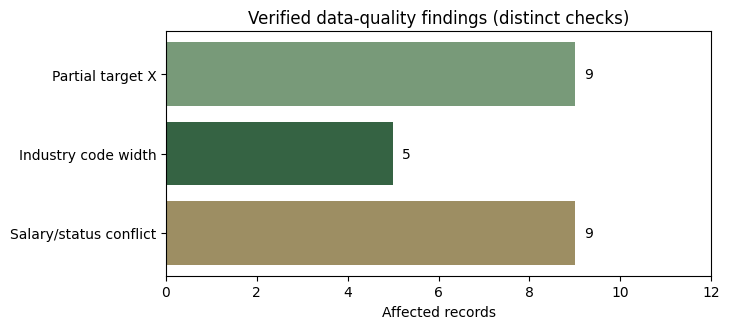

In [8]:
salary_field = metadata.loc[
    metadata["הסבר"].fillna("").str.contains("רק במידה",regex=False),"משתנה"
].tolist()
assert salary_field == ["MakorSachar"]
assert "MaamadAvoda" in str(contracts.loc["MakorSachar","הסבר"])
status_codes = enumerations["MaamadAvoda"]
salary_applicable_codes = {number for number,meaning in status_codes.items()
                           if "שכיר" in meaning or "חבר קואופרטיב" in meaning}
assert salary_applicable_codes == {1,5}, "Check the source's employment-status semantics"
status = pd.to_numeric(survey["MaamadAvoda"],errors="coerce")
salary_present = occupied(survey["MakorSachar"])
not_applicable = status.notna() & ~status.isin(salary_applicable_codes)
invalid_salary_context = not_applicable & salary_present
unknown_salary_context = status.isna() & salary_present
print("Applicable statuses (read from Metadata labels):",salary_applicable_codes)
print("Salary-source conflicts:",int(invalid_salary_context.sum()))
print("Salary source with unknown status:",int(unknown_salary_context.sum()))
print("IDs of rule conflicts:",survey.loc[invalid_salary_context,"ID"].astype(int).tolist())
assert invalid_salary_context.sum()==9
assert not unknown_salary_context.any()

industry_flags=validate_type(survey,"SemelAnafSofi")
target_flags=validate_type(survey,TARGET)
complete_mask = occupied(survey[TARGET]) & ~target_flags["partial_X_code"] & ~target_flags["code_shape_mismatch"]
partial_mask = target_flags["partial_X_code"]
assert int(complete_mask.sum())==191 and int(partial_mask.sum())==9
print("Four-character target labels:",int(complete_mask.sum()),
      "| target labels containing X:",int(partial_mask.sum()))
print("Industry code-shape mismatches:",int(industry_flags["code_shape_mismatch"].sum()))
print("Industry X partial codes:",int(industry_flags["partial_X_code"].sum()))

cross_issues=pd.DataFrame({"ID":survey.loc[invalid_salary_context,"ID"].astype(int),
                           "field":"MakorSachar","rule":"salary_status_applicability",
                           "source":"Metadata description and MaamadAvoda enumerated labels"})
issue_totals=(pd.concat([issues[["ID","field","rule"]],cross_issues[["ID","field","rule"]]],
                       ignore_index=True)
                .groupby(["field","rule"]).size().rename("records").reset_index())
display(issue_totals)

fig,ax=plt.subplots(figsize=(7.4,3.4))
keys=["Partial target X","Industry code width","Salary/status conflict"]
vals=[int(partial_mask.sum()),int(industry_flags["code_shape_mismatch"].sum()),int(invalid_salary_context.sum())]
ax.barh(keys[::-1],vals[::-1],color=[PALETTE["orange"],PALETTE["blue"],PALETTE["teal"]])
ax.set(xlabel="Affected records",title="Verified data-quality findings (distinct checks)")
for i,value in enumerate(vals[::-1]):ax.text(value+.2,i,str(value),va="center")
ax.set_xlim(0,max(vals)+3)
fig.tight_layout();plt.show()

## 9. כפילויות ותוויות סותרות
המסמך מתאר שידורים חוזרים. אולם `ID` הוא "מספר רץ" לפי Metadata ואינו מזהה משתתף יציב, ואין תאריך שידור. לפיכך אי אפשר להסיק שמספר שורות שייכות לאותו אדם. כתחליף מוגבל נבנית חתימה של שבעה שדות תיאור, המשמשת רק לבדיקת דמיון ולחלוקת אימון/בדיקה מופרדת קבוצות. כל שינוי בתיאורי הסקר עלול ליצור קבוצה חדשה גם אם מדובר באותו משתתף.

In [9]:
assert pd.to_numeric(survey["ID"],errors="coerce").is_unique
GROUP_FIELDS=["ShemAvoda","SugAvoda","ShemMachlaka","SugMachlaka",
              "EzoAvoda","TeurPeula","TeurTafkid"]
def normal_signature(x):
    if pd.isna(x): return ""
    return " ".join(re.sub(r"[^\w\u0590-\u05ff]+"," ",str(x).lower()).split())
groups=survey[GROUP_FIELDS].apply(
    lambda row:"|".join(normal_signature(row[k]) for k in GROUP_FIELDS),axis=1)
clusters=(survey.assign(group_signature=groups)
          .groupby("group_signature",dropna=False)
          .agg(records=("ID","size"),distinct_target_labels=(TARGET,"nunique")))
print("Description groups:",len(clusters),
      "| groups repeated:",int(clusters.records.gt(1).sum()),
      "| conflicting-label groups:",int(clusters.distinct_target_labels.gt(1).sum()))
conflict_keys=set(clusters.index[clusters.distinct_target_labels.gt(1)])
display(survey.loc[groups.isin(conflict_keys),["ID","ShemAvoda","EzoAvoda",TARGET]])

Description groups: 137 | groups repeated: 40 | conflicting-label groups: 1


,ID,ShemAvoda,EzoAvoda,SemelMishlachSofi
1,2.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3311
32,33.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
64,65.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
95,96.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211


## 10. אישור החלטות על תכונות — מבוסס סוג, אך אינו מוכתב רק ממנו
**הפרדת תחומי אחריות:** `TEXT` מפעיל בדיקות טקסט אבל אינו אומר שכל טקסט צריך להיכלל במודל; `INTEGER` עם ערכים ממוספרים הוא *משתנה קטגוריאלי* ולא ערך רציף. זמינות השדה בזמן אמת והסיכון לזליגה נקבעים לפי משמעותו ותהליך הסימול.

המודל משתמש בשישה תיאורי עבודה, בארבעה שדות עם קודים ממוספרים ובשנות לימוד. `ID` הוא זיהוי בלבד; שם המעסיק והיישוב נשארים לצורכי ביקורת וקיבוץ; גיל ותאריך התחלה מוצגים אך אינם תכונות במודל הבסיסי; `SemelAnafSofi` מוחרג כי זמינות הסמל הענפי הסופי לפני סיווג משלח היד אינה מוכחת; היעד לעולם אינו נכלל בתכונות. זו **מדיניות אנליטית מפורשת**, לא תוכן שהמצאנו ל-Metadata.

In [10]:
APPROVED_TEXT=["SugAvoda","ShemMachlaka","SugMachlaka",
               "EzoAvoda","TeurPeula","TeurTafkid"]
APPROVED_CATEGORICAL=["MenahelEtMi","MaamadAvoda","MakorSachar","TeudaGvoha"]
APPROVED_NUMERIC=["shnotlimud"]
FEATURES=APPROVED_TEXT+APPROVED_CATEGORICAL+APPROVED_NUMERIC
EXCLUDED=[name for name in survey.columns if name not in FEATURES]
assert len(FEATURES)==11 and len(EXCLUDED)==7
assert all(contracts.loc[name,"פורמט"]=="TEXT" and not widths[name] for name in APPROVED_TEXT)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and bool(enumerations[name])
           for name in APPROVED_CATEGORICAL)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and not enumerations[name]
           for name in APPROVED_NUMERIC)
assert TARGET in EXCLUDED and "SemelAnafSofi" in EXCLUDED

for name in survey.columns:
    role=("TEXT_TFIDF" if name in APPROVED_TEXT else
          "NOMINAL_ONE_HOT" if name in APPROVED_CATEGORICAL else
          "NUMERIC_IMPUTE_SCALE" if name in APPROVED_NUMERIC else
          "TARGET_NOT_FEATURE" if name==TARGET else
          "AUDIT_AND_GROUP_ONLY" if name=="ShemAvoda" else
          "AUDIT_EXCLUDED")
    r=summary.loc[summary.field.eq(name)].iloc[0]
    print(f"{name:20} Metadata={r['type']:7} Role={role:22} "
          f"Missing={r['missing']:3} Type issues={r['violations']:2}")

ID                   Metadata=INTEGER Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
YeshuvAvoda          Metadata=TEXT    Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
ShemAvoda            Metadata=TEXT    Role=AUDIT_AND_GROUP_ONLY   Missing=  0 Type issues= 0
SugAvoda             Metadata=TEXT    Role=TEXT_TFIDF             Missing= 25 Type issues= 0
ShemMachlaka         Metadata=TEXT    Role=TEXT_TFIDF             Missing= 64 Type issues= 0
SugMachlaka          Metadata=TEXT    Role=TEXT_TFIDF             Missing=134 Type issues= 0
EzoAvoda             Metadata=TEXT    Role=TEXT_TFIDF             Missing=  7 Type issues= 0
TeurPeula            Metadata=TEXT    Role=TEXT_TFIDF             Missing=136 Type issues= 0
TeurTafkid           Metadata=TEXT    Role=TEXT_TFIDF             Missing=172 Type issues= 0
MenahelEtMi          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Missing=168 Type issues= 0
MaamadAvoda          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Miss

## 11. ניסוי V3 — צבירה של כל שדה תיאור טקסטואלי בנפרד
נבחנות שתי חלופות **על אותן רשומות אימון ובדיקה**: (א) V2 עם TF-IDF ישיר למודל, ו-(ב) V3 עם TF-IDF → KMeans → מזהה אשכול → OneHotEncoder. ארבעת השדות הקודיים ושנות הלימוד מקבלים את אותם עיבודים בשתי החלופות.

כל ערך טקסט **ייחודי ולא ריק** נכנס פעם אחת לבחירת K באותו שדה. כך חזרות מילוליות של אותו ערך אינן משנות את ניקוד Calinski–Harabasz. לאחר בחירת K ממפים *את כל רשומות האימון* לאשכול המתאים. בחיזוי, טקסט שלא נראה באימון מוקצה למרכז הקרוב שנלמד באימון. חסר נשמר כקטגוריה נפרדת, **לא** כערך מספרי.

הקריטריון Calinski–Harabasz הוא יחס פיזור בין אשכולות לפיזור בתוך אשכולות, לא מבחן F סטטיסטי לנכונות סמנטית ולא הוכחה שצירוף תיאורים מייצג אותו משלח יד. בדיקת משמעות מקצועית מתבצעת בנפרד לפי החברים בכל אשכול.

**מגבלת חישוב מנומקת:** עבור מספר וקטורים ייחודיים תקינים `u`, נבדקים כל `K=2,...,min(100,20,floor(2u/3),u-1)`. 100 הוא תקרת הבטיחות שביקשת; 20 הוא תקציב ריצה שמרני ל-200 שורות. הטווח המוצהר נבדק **במלואו**, ללא בחירת דגימה של ערכי K. כשאין מספיק ערכים, אין ממציאים אשכולות: מופעל מסלול קטגוריאלי חלופי.

**בחירה מדויקת:** נבחר ניקוד ה-CH המקסימלי לאחר עיגול ל-2 ספרות אחרי הנקודה. לניקוד קטן מ-1 מתרחבת הרזולוציה כדי לשמר הבדלים קטנים בעלי משמעות מספרית. בשוויון הניקוד המעוגל נבחר **K הקטן**. כלל זה מוגדר מראש לפי בקשתך; הוא אינו מניח שאשכול K קטן תמיד נכון יותר.

**גאומטריית הנרמול:** `norm="l2"` מחלק כל וקטור TF-IDF לא־אפס בנורמה האוקלידית שלו. לכן, לשני וקטורים מנורמלים, מכפלה פנימית שווה לדמיון קוסינוס. מטריצת Gram (`XXᵀ`) מכילה 1 על האלכסון, אך אינה בהכרח מטריצת היחידה, משום שהערכים מחוץ לאלכסון עשויים להיות שונים מאפס. שים לב כי KMeans סטנדרטי מחפש מרכזים אוקלידיים, ולא מרכזים מוכרחים להיות מנורמלים.

**השוואת החלקת IDF:** `smooth_idf=True` (ברירת המחדל) ו-`False` נבחנות כמועמדים נפרדים, כאשר כל יתר הפרמטרים, הפיצול, הדוחות וכללי K נשמרים זהים. IDF smoothing משנה את משקל רצפי התווים, בעוד שנרמול L2 שולט בנורמת הווקטור. ההשוואה על קבוצת הבדיקה היא אקספלורטורית ואינה אימות בלתי תלוי אחרי בחירת המועמד הטוב ביותר.


In [11]:
NO_SIGNAL_TEXT={"כנ\"ל","כנ״ל","חסוי","לא יכול לפרט","0"}

def model_features(frame):
    result=pd.DataFrame(index=frame.index)
    for field in APPROVED_TEXT:
        x=frame[field].astype("string").fillna("")
        x=x.str.replace(r"\s+"," ",regex=True).str.strip()
        result[field]=x.mask(x.isin(NO_SIGNAL_TEXT),"").astype(str)
    for field in APPROVED_CATEGORICAL:
        x=pd.to_numeric(frame[field],errors="coerce").astype("Int64")
        result[field]=x.astype("string").fillna("MISSING").astype(str)
    applicable=pd.to_numeric(frame["MaamadAvoda"],errors="coerce").isin(salary_applicable_codes)
    is_unknown=frame["MaamadAvoda"].isna()
    result.loc[~applicable & ~is_unknown,"MakorSachar"]="NOT_APPLICABLE"
    result.loc[is_unknown,"MakorSachar"]="APPLICABILITY_UNKNOWN"
    for field in APPROVED_NUMERIC:
        result[field]=pd.to_numeric(frame[field],errors="coerce")
    return result[FEATURES]

# Existing V2 representation serves as a fixed comparator, not a source of ground truth.
def fresh_tfidf_baseline(smooth_idf=True):
    text_steps=[(f"char_{field}",
                 TfidfVectorizer(analyzer="char",ngram_range=(2,4),
                                 max_features=4000,sublinear_tf=True,
                                 norm="l2",smooth_idf=smooth_idf),field)
                for field in APPROVED_TEXT]
    pre=ColumnTransformer(
        transformers=[*text_steps,
                      ("categorical",OneHotEncoder(handle_unknown="ignore"),APPROVED_CATEGORICAL),
                      ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),
                                           ("scale",StandardScaler())]),APPROVED_NUMERIC)],
        sparse_threshold=1.0)
    return Pipeline([("features",pre),
                     ("estimator",LogisticRegression(C=1.0,max_iter=1200,random_state=SEED))])

MAX_K_HARD=100
MAX_K_RUNTIME=20
K_RATIO=2/3

def score_decimals(scores):
    """Two decimals normally; increase precision when CH scores are small."""
    finite=[abs(float(v)) for v in scores if np.isfinite(v)]
    biggest=max(finite,default=0.0)
    if biggest==0.0: return 8
    return min(8,max(2, 2-int(np.floor(np.log10(biggest)))))

def select_optimal_k(candidate_scores):
    """Return best (k, score, rounded_score, decimals), with smaller k on ties."""
    finite=[(int(k),float(v)) for k,v in candidate_scores if np.isfinite(v)]
    if not finite:return None
    digits=score_decimals([v for _,v in finite])
    winners=sorted([(k,v,round(v,digits),digits) for k,v in finite],
                   key=lambda row:(-row[2],row[0]))
    return winners[0]

# Guard the exact requested ordering and small-score behavior.
assert select_optimal_k([(2, 18.1231),(6,18.1244)])[0]==2
assert select_optimal_k([(2, .000105),(3,.000117)])[0]==3
assert score_decimals([.0001])>=5

class PerColumnTFIDFClusters(BaseEstimator,TransformerMixin):
    """Unsupervised per-column KMeans fit exclusively on the training fold.

    Each unique observed non-empty text gets one vote in CH selection.
    Transform returns string-valued NOMINAL cluster categories; its consumer
    must apply OneHotEncoder before classifier training.
    """
    def __init__(self, fields, ratio=K_RATIO, hard_max=MAX_K_HARD,
                 runtime_max=MAX_K_RUNTIME, random_state=SEED,
                 n_init=5, max_iter=120, max_features=1200, smooth_idf=True):
        self.fields=fields
        self.ratio=ratio
        self.hard_max=hard_max
        self.runtime_max=runtime_max
        self.random_state=random_state
        self.n_init=n_init
        self.max_iter=max_iter
        self.max_features=max_features
        self.smooth_idf=smooth_idf

    def fit(self,X,y=None):
        frame=pd.DataFrame(X,columns=self.fields).copy()
        self.models_={}
        score_rows=[]
        summary_rows=[]
        for field in self.fields:
            values=sorted(v for v in frame[field].fillna("").astype(str).unique() if v.strip())
            entry={"field":field,"known_values":values,"lookup":{}}
            if len(values)<3:
                entry.update(kind="few_values",selected_k=None,distinct_vectors=len(values),
                             vectorizer=None,clusterer=None)
                entry["lookup"]={v:f"value_{i:03d}" for i,v in enumerate(values)}
                self.models_[field]=entry
                summary_rows.append({"field":field,"distinct_texts":len(values),
                                     "distinct_vectors":len(values),"candidates":0,
                                     "chosen_k":np.nan,"score":np.nan,
                                     "digits":np.nan,"status":"too_few_distinct_values"})
                continue
            vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(2,4),
                                       sublinear_tf=True,max_features=self.max_features,
                                       norm="l2",smooth_idf=self.smooth_idf)
            vectors=vectorizer.fit_transform(values).toarray()
            # L2-norm audit: diagonal of the Gram matrix is 1 for nonzero vectors,
            # but off-diagonal similarities are generally nonzero.
            norms=np.linalg.norm(vectors,axis=1)
            assert np.allclose(norms,1.0,atol=1e-12)
            gram=vectors@vectors.T
            assert np.allclose(np.diag(gram),1.0,atol=1e-12)
            assert np.all(gram<=1.0+1e-12)
            entry["mean_offdiagonal_cosine"]=float((gram.sum()-np.trace(gram))/(len(values)*(len(values)-1)))
            distinct_vectors=len(np.unique(np.round(vectors,12),axis=0))
            max_k=min(self.hard_max,self.runtime_max,
                      int(np.floor(self.ratio*distinct_vectors)),distinct_vectors-1)
            if max_k<2:
                entry.update(kind="few_values",selected_k=None,distinct_vectors=distinct_vectors,
                             vectorizer=None,clusterer=None)
                entry["lookup"]={v:f"value_{i:03d}" for i,v in enumerate(values)}
                self.models_[field]=entry
                summary_rows.append({"field":field,"distinct_texts":len(values),
                                     "distinct_vectors":distinct_vectors,"candidates":0,
                                     "chosen_k":np.nan,"score":np.nan,
                                     "digits":np.nan,"status":"insufficient_separation"})
                continue
            candidates=[]
            candidate_models={}
            for k in range(2,max_k+1):
                clustering=KMeans(n_clusters=k,init="k-means++",n_init=self.n_init,
                                  max_iter=self.max_iter,random_state=self.random_state,
                                  algorithm="lloyd")
                labels=clustering.fit_predict(vectors)
                if not (2<=len(np.unique(labels))<len(values)):
                    score_rows.append({"field":field,"k":k,"ch_score":np.nan,
                                       "used":False,"reason":"degenerate_assignment"})
                    continue
                score=float(calinski_harabasz_score(vectors,labels))
                score_rows.append({"field":field,"k":k,"ch_score":score,
                                   "used":bool(np.isfinite(score)),"reason":""})
                if np.isfinite(score):
                    candidates.append((k,score))
                    candidate_models[k]=clustering
            best=select_optimal_k(candidates)
            if best is None:
                entry.update(kind="few_values",selected_k=None,
                             distinct_vectors=distinct_vectors,vectorizer=None,clusterer=None)
                entry["lookup"]={v:f"value_{i:03d}" for i,v in enumerate(values)}
                status="no_valid_ch_score"
                chosen_k=np.nan;chosen_score=np.nan;precision=np.nan
            else:
                chosen_k,chosen_score,rounded,precision=best
                chosen_model=candidate_models[chosen_k]
                entry.update(kind="kmeans",vectorizer=vectorizer,clusterer=chosen_model,
                             selected_k=chosen_k,selected_ch=chosen_score,
                             scoring_decimals=precision,distinct_vectors=distinct_vectors)
                entry["lookup"]={v:f"cluster_{int(k):03d}"
                                 for v,k in zip(values,chosen_model.labels_)}
                status="fitted"
            self.models_[field]=entry
            summary_rows.append({"field":field,"distinct_texts":len(values),
                                 "distinct_vectors":distinct_vectors,"candidates":len(candidates),
                                 "chosen_k":chosen_k,"score":chosen_score,
                                 "digits":precision,"status":status})
        self.ch_scores_=pd.DataFrame(score_rows)
        self.summary_=pd.DataFrame(summary_rows)
        self.n_features_in_=len(self.fields)
        self.feature_names_in_=np.asarray(self.fields,dtype=object)
        return self

    def transform(self,X):
        if not hasattr(self,"models_"):
            raise RuntimeError("Fit clusters on training data before transform")
        frame=pd.DataFrame(X,columns=self.fields)
        encoded=np.empty((len(frame),len(self.fields)),dtype=object)
        for col_idx,field in enumerate(self.fields):
            entry=self.models_[field]
            values=frame[field].fillna("").astype(str).str.strip()
            result=[]
            for value in values:
                if not value:
                    result.append("MISSING")
                elif value in entry["lookup"]:
                    result.append(entry["lookup"][value])
                elif entry["kind"]=="kmeans":
                    code=entry["clusterer"].predict(entry["vectorizer"].transform([value]))[0]
                    result.append(f"cluster_{int(code):03d}")
                else:
                    result.append("UNSEEN_VALUE")
            encoded[:,col_idx]=result
        assert encoded.shape==(len(frame),len(self.fields))
        return encoded

    def get_feature_names_out(self,input_features=None):
        return np.asarray(self.fields,dtype=object)


def fresh_cluster_model(smooth_idf=True):
    cluster_branch=Pipeline([
        ("assign",PerColumnTFIDFClusters(fields=tuple(APPROVED_TEXT), smooth_idf=smooth_idf)),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))])
    pre=ColumnTransformer([
        ("clustered_text",cluster_branch,APPROVED_TEXT),
        ("categorical",OneHotEncoder(handle_unknown="ignore"),APPROVED_CATEGORICAL),
        ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),
                             ("scale",StandardScaler())]),APPROVED_NUMERIC)
    ],sparse_threshold=1.0)
    return Pipeline([("features",pre),
                     ("estimator",LogisticRegression(C=1.0,max_iter=1200,
                                                       random_state=SEED))])
assert model_features(survey).columns.tolist()==FEATURES
print("V3: per-column TF-IDF (L2, IDF smoothing controlled) -> full K range -> CH -> cluster IDs -> OneHot")
print("K bounds: min(100,20,floor(2/3 distinct vectors), distinct vectors-1)")

V3: per-column TF-IDF (L2, IDF smoothing controlled) -> full K range -> CH -> cluster IDs -> OneHot
K bounds: min(100,20,floor(2/3 distinct vectors), distinct vectors-1)


## 12. חלוקה לפי תיאור, בחירת K, אימון והערכה על נתונים שלא נצפו
החיפוש אחר K מתבצע **בכל אחת משש עמודות הטקסט ובתוך האימון בלבד**, כולל התאמת TF-IDF ו-KMeans. שדות אחרים עוברים OneHotEncoder ותקנון בדיוק כמו ב-V2. אין שימוש בעמודת היעד לבחירת אשכולות, ולכן אשכולות אינם סמלי מקצוע. גם הציון CH וגם מספר האשכולות נקבעים על נתוני אימון בלבד.

ההשוואה בין שתי החלופות מתבצעת על קבוצת בדיקה זהה. התוצאה אינה בסיס לבחירת מודל להטמעה, משום שמדובר בדוגמה זעירה ומתויגת ברעש. קטגוריות שלא נראו באימון וקודים חלקיים נשמרים בשקיפות.

**אופן המדידה:** נציג ארבע חלופות (TF-IDF ישיר/אשכולות, עם/ללא החלקת IDF) לצד Dummy, על אותם 42 מקרי בדיקה. נבחן Macro-F1 ו-Macro-Recall — שכל אחד מהם נותן משקל שווה למחלקות, לצד Weighted-F1. בבעיה רב-מחלקתית עם תווית אמת אחת לכל רשומה, Weighted-Recall זהה ל-Accuracy; נציג זאת ונמנע מפרשנות של שיפור נפרד במדד זה.


TRAIN: 149 TEST: 42 TEST LABELS UNSEEN IN TRAIN: 8
L2 normalization is explicit for every text vectorizer.
Candidate comparison is exploratory; do not select on holdout and report same holdout as unbiased validation.


,model,correct,accuracy,macro_precision,macro_recall,macro_f1,weighted_recall,weighted_f1
0,Dummy classifier,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,direct: smooth_idf=True,31,0.7381,0.4737,0.5185,0.4879,0.7381,0.6973
2,direct: smooth_idf=False,31,0.7381,0.4737,0.5185,0.4879,0.7381,0.6973
3,clusters: smooth_idf=True,29,0.6905,0.4524,0.4881,0.4619,0.6905,0.6556
4,clusters: smooth_idf=False,32,0.7619,0.5101,0.5556,0.5231,0.7619,0.7271


CLUSTER BRANCH: nominal string IDs -> OneHotEncoder -> classifier


,field,distinct_texts,distinct_vectors,candidates,chosen_k,score,digits,status
0,SugAvoda,64,64,19,3,1.87745,2,fitted
1,ShemMachlaka,50,50,19,9,1.44002,2,fitted
2,SugMachlaka,27,27,17,2,1.60842,2,fitted
3,EzoAvoda,67,67,19,16,1.83728,2,fitted
4,TeurPeula,24,24,15,16,1.56823,2,fitted
5,TeurTafkid,10,10,5,2,1.15165,2,fitted


All holdout predictions (default smooth_idf=True models shown):


,ID,manual_code,tfidf_baseline,cluster_model,matches_given_code
0,12,2631,2631,2631,True
1,13,5131,5131,5223,False
2,16,5223,5223,5223,True
3,25,3323,5322,2655,False
4,27,9112,9112,9112,True
5,28,5120,5120,5120,True
6,36,5322,5322,5322,True
7,38,3122,3122,3122,True
8,41,2514,2514,2514,True
9,48,5223,5223,5223,True


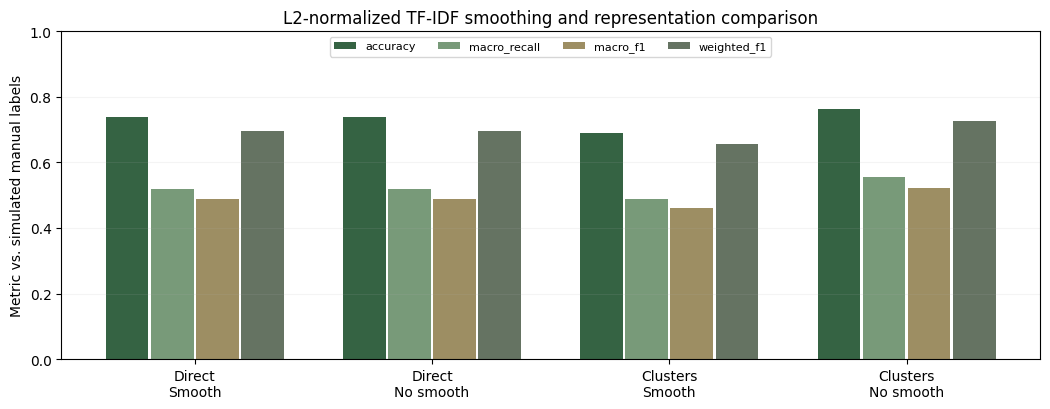

In [12]:
complete=survey.loc[complete_mask].copy()
partial=survey.loc[partial_mask].copy()
X=model_features(complete)
y=complete[TARGET].astype(str)
assigned_groups=groups.loc[complete.index]
train_idx,test_idx=next(GroupShuffleSplit(n_splits=1,test_size=.22,random_state=SEED)
                        .split(X,y,groups=assigned_groups))
assert set(assigned_groups.iloc[train_idx]).isdisjoint(set(assigned_groups.iloc[test_idx]))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]

baseline=DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
fitted_direct={}
fitted_cluster={}
forecast_by_setting={}
for smoothing in [True,False]:
    fitted_direct[smoothing]=fresh_tfidf_baseline(smooth_idf=smoothing).fit(X_train,y_train)
    fitted_cluster[smoothing]=fresh_cluster_model(smooth_idf=smoothing).fit(X_train,y_train)
    forecast_by_setting[("direct",smoothing)]=fitted_direct[smoothing].predict(X_test)
    forecast_by_setting[("clusters",smoothing)]=fitted_cluster[smoothing].predict(X_test)

tfidf_baseline=fitted_direct[True]
model=fitted_cluster[True]
base_forecast=baseline.predict(X_test)
tfidf_forecast=forecast_by_setting[("direct",True)]
forecast=forecast_by_setting[("clusters",True)]
probability_score=model.predict_proba(X_test).max(axis=1)
not_seen=~y_test.isin(set(y_train))

from sklearn.metrics import precision_score, recall_score

def metric_line(name,pred):
    return {"model":name,
            "correct":int(np.sum(y_test.to_numpy()==pred)),
            "accuracy":accuracy_score(y_test,pred),
            "macro_precision":precision_score(y_test,pred,average="macro",zero_division=0),
            "macro_recall":recall_score(y_test,pred,average="macro",zero_division=0),
            "macro_f1":f1_score(y_test,pred,average="macro",zero_division=0),
            "weighted_recall":recall_score(y_test,pred,average="weighted",zero_division=0),
            "weighted_f1":f1_score(y_test,pred,average="weighted",zero_division=0)}

performance=pd.DataFrame([metric_line("Dummy classifier",base_forecast)] + [
    metric_line(f"{branch}: smooth_idf={smooth}",forecast_by_setting[(branch,smooth)])
    for branch in ["direct","clusters"] for smooth in [True,False]
])
assert all(np.isclose(performance.weighted_recall,performance.accuracy))
print("TRAIN:",len(train_idx),"TEST:",len(test_idx),
      "TEST LABELS UNSEEN IN TRAIN:",int(not_seen.sum()))
print("L2 normalization is explicit for every text vectorizer.")
print("Candidate comparison is exploratory; do not select on holdout and report same holdout as unbiased validation.")
display(performance.round(4))

cluster_branch=model.named_steps["features"].named_transformers_["clustered_text"]
clusterer=cluster_branch.named_steps["assign"]
nominal_clusters=cluster_branch.named_steps["onehot"]
assert len(clusterer.models_)==len(APPROVED_TEXT)
raw_cluster_assignments=clusterer.transform(X_test[APPROVED_TEXT])
assert raw_cluster_assignments.dtype==object
encoded_cluster_matrix=nominal_clusters.transform(raw_cluster_assignments)
assert encoded_cluster_matrix.shape[0]==len(X_test)
assert set(np.unique(encoded_cluster_matrix.toarray() if hasattr(encoded_cluster_matrix,"toarray")
                     else encoded_cluster_matrix)).issubset({0,1})
print("CLUSTER BRANCH: nominal string IDs -> OneHotEncoder -> classifier")
display(clusterer.summary_.round(5))

held_out=pd.DataFrame({"ID":complete.iloc[test_idx]["ID"].astype(int).to_numpy(),
                       "manual_code":y_test.to_numpy(),
                       "tfidf_baseline":tfidf_forecast,
                       "cluster_model":forecast,
                       "matches_given_code":forecast==y_test.to_numpy(),
                       "class_seen_in_training":~not_seen.to_numpy(),
                       "uncalibrated_score":np.round(probability_score,3)})
assert held_out.shape[0]==len(test_idx)
print("All holdout predictions (default smooth_idf=True models shown):")
display(held_out[["ID","manual_code","tfidf_baseline","cluster_model","matches_given_code"]].reset_index(drop=True))

fig,ax=plt.subplots(figsize=(10.6,4.2))
plot=performance.iloc[1:].reset_index(drop=True)
inds=np.arange(len(plot))
metrics=["accuracy","macro_recall","macro_f1","weighted_f1"]
for j,m in enumerate(metrics):
    ax.bar(inds+(j-1.5)*.19,plot[m],.18,label=m,
           color=[PALETTE["blue"],PALETTE["teal"],PALETTE["orange"],PALETTE["gray"]][j])
ax.set_xticks(inds,labels=["Direct\nSmooth","Direct\nNo smooth","Clusters\nSmooth","Clusters\nNo smooth"])
ax.set(ylim=(0,1),ylabel="Metric vs. simulated manual labels",title="L2-normalized TF-IDF smoothing and representation comparison")
ax.legend(ncol=4,fontsize=8,loc="upper center");ax.grid(axis="y",alpha=.13)
fig.tight_layout();plt.show()

## 13. עקומות CH מלאות ובדיקת קשר בין מספר האשכולות לציון
לכל עמודה מציגים את **כל** K שנבדק, לא רק את המקסימום, וכן את K שנבחר. הכוכבית היא בחירה לפי הניקוד המעוגל ברזולוציה המתאימה, ולכן היא עשויה להיות שונה ממקסימום הספרות הלא מעוגלות. ציוני CH בין עמודות אינם בני-השוואה ישירה משום שממד, תפוצה ומספר ערכים שונים.

בחרנו לכל שדה לכל היותר 20 אשכולות מטעמי תקציב חישובי. זהו גבול **חיפוש** ולא קביעה ש-20 הוא המספר הנכון. היעדר בדיקה מעבר לו הוא מגבלה מוצהרת.

לאחר השוואת `smooth_idf=True/False`, עקומת CH הראשית ממשיכה להציג את גרסת ברירת המחדל (`True`), ובטבלת ההשוואה נציג לצד כל שדה את K שנבחר בכל הגדרה. שני התהליכים שווים בכל רכיב אחר, לרבות `norm="l2"`, גודל מרחב התכונות, תקרת K וזרע אקראי.


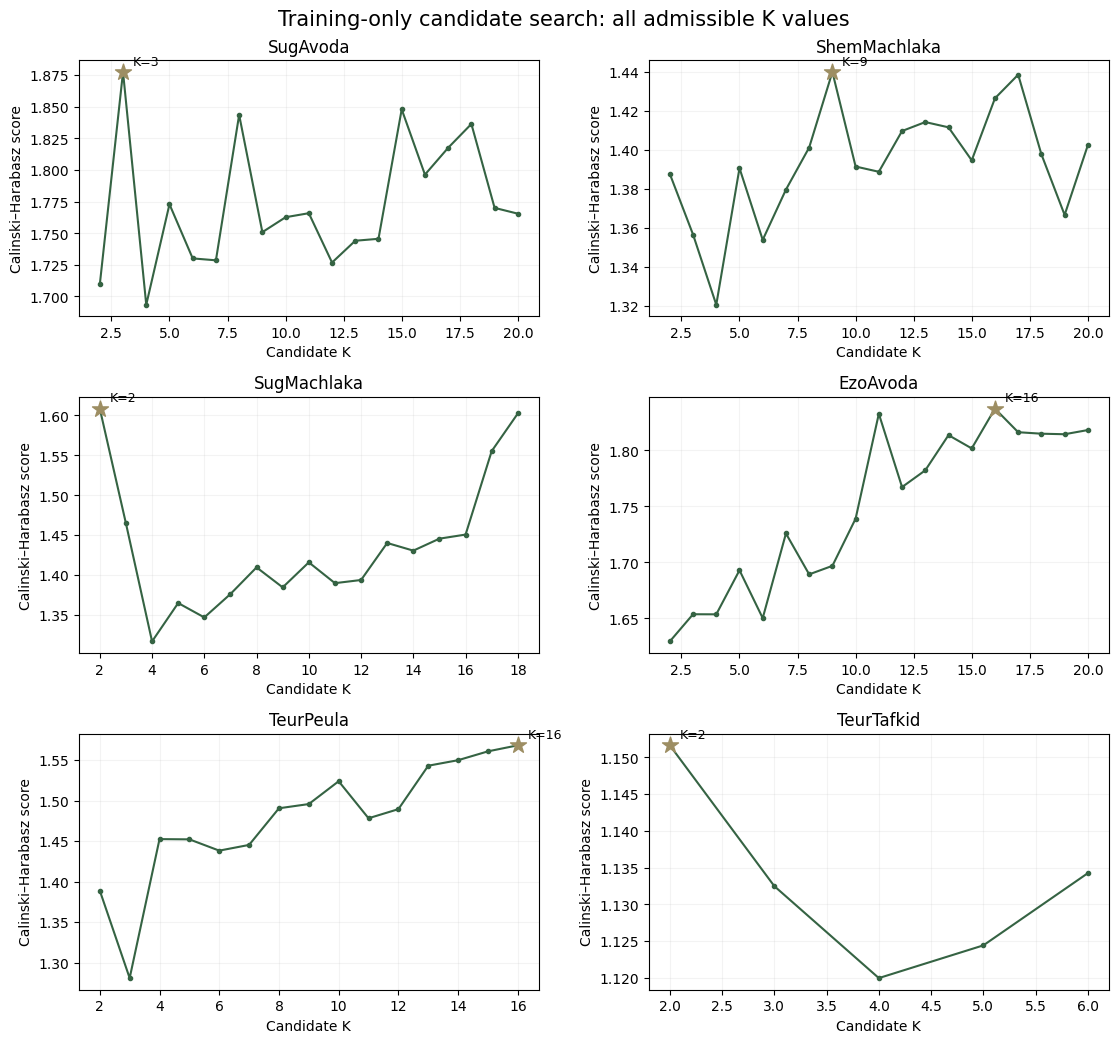

SugAvoda: 19 candidate K; selected=3; CH=1.88; decimal_precision=2
ShemMachlaka: 19 candidate K; selected=9; CH=1.44; decimal_precision=2
SugMachlaka: 17 candidate K; selected=2; CH=1.61; decimal_precision=2
EzoAvoda: 19 candidate K; selected=16; CH=1.84; decimal_precision=2
TeurPeula: 15 candidate K; selected=16; CH=1.57; decimal_precision=2
TeurTafkid: 5 candidate K; selected=2; CH=1.15; decimal_precision=2
L2-normalized CH selection by IDF smoothing:


,field,K_smooth,CH_smooth,K_no_smooth,CH_no_smooth
0,SugAvoda,3,1.8774,4,1.8778
1,ShemMachlaka,9,1.4400,17,1.3957
2,SugMachlaka,2,1.6084,18,1.5340
3,EzoAvoda,16,1.8373,18,1.7901
4,TeurPeula,16,1.5682,15,1.5173
5,TeurTafkid,2,1.1517,2,1.1282


In [13]:
all_ch=clusterer.ch_scores_.copy()
assert all_ch.groupby("field").size().max()<=MAX_K_RUNTIME-1
assert all_ch.groupby("field").size().max()<=MAX_K_HARD-1
fig,axs=plt.subplots(3,2,figsize=(11.2,10.6))
for ax,field in zip(axs.ravel(),APPROVED_TEXT):
    sub=all_ch.loc[(all_ch.field==field)&all_ch.used].sort_values("k")
    info=clusterer.models_[field]
    if len(sub):
        ax.plot(sub.k,sub.ch_score,marker="o",ms=3,color=PALETTE["blue"])
        chosen=int(info["selected_k"])
        winner=sub.loc[sub.k.eq(chosen)].iloc[0]
        ax.scatter([chosen],[winner.ch_score],marker="*",s=145,color=PALETTE["orange"],zorder=3)
        ax.annotate(f"K={chosen}",(chosen,winner.ch_score),xytext=(7,5),textcoords="offset points",fontsize=9)
    ax.set(title=field,xlabel="Candidate K",ylabel="Calinski–Harabasz score")
    ax.grid(alpha=.15)
fig.suptitle("Training-only candidate search: all admissible K values",fontsize=15)
fig.tight_layout();plt.show()
for field in APPROVED_TEXT:
    info=clusterer.models_[field]
    if info["kind"]=="kmeans":
        scores=all_ch.loc[(all_ch.field==field)&all_ch.used]
        best=select_optimal_k(list(zip(scores.k,scores.ch_score)))
        assert best[0]==info["selected_k"]
        print(f"{field}: {len(scores)} candidate K; selected={best[0]}; "
              f"CH={best[1]:.{best[3]}f}; decimal_precision={best[3]}")

# Sensitivity of selected K to the IDF smoothing setting.
clusterer_nosmooth=fitted_cluster[False].named_steps["features"].named_transformers_["clustered_text"].named_steps["assign"]
smooth_compare=clusterer.summary_[["field","chosen_k","score"]].rename(columns={
    "chosen_k":"K_smooth","score":"CH_smooth"}).merge(
    clusterer_nosmooth.summary_[["field","chosen_k","score"]].rename(columns={
        "chosen_k":"K_no_smooth","score":"CH_no_smooth"}),on="field",validate="one_to_one")
print("L2-normalized CH selection by IDF smoothing:")
display(smooth_compare.round(4))
assert smooth_compare.field.nunique()==len(APPROVED_TEXT)


## 14. בדיקת תוכן האשכולות — דוגמאות מקצועיות ולא טענת שקילות סמנטית
המספר שהחזיר KMeans הוא **מזהה קטגוריה בלבד**, ולא גודל כמותי. הרשימה שלהלן מציגה את התיאורים שהאשכול צירף, בלי לאחד פיזית או לשכתב אף ערך במקור. רק סמלן מקצועי, או סט אמת-מידה מוערך באופן בלתי תלוי, יכול לקבוע אם האשכול מהווה קטגוריה מקצועית תקינה.

כבדיקת היגיון מקומית, נבחנות דוגמאות המתייחסות לתוכנה, לתכנות ולמשרות דומות. TF-IDF תווי מסוגל לאתר תבניות משותפות, אך לא לזהות סמנטיקה מקצועית ללא ראיות נוספות. גם אם שני תיאורים הוקצו לאשכול משותף, **אין לשנות בשל כך את תוויות היעד המקוריות**.

נבחן בהשוואה גם האם החלקת IDF שינתה את ההקצאה של תיאורי תוכנה שכיחים. השוואת מזהי האשכולות **בין מודלים נפרדים אינה השוואה מספרית**: כל KMeans בוחר שמות שרירותיים, ולכן נשווה צמדי ערכים הנמצאים באותו אשכול בתוך כל פתרון, ולא את מספרי המזהים עצמם.


In [14]:
member_rows=[]
for field in APPROVED_TEXT:
    entry=clusterer.models_[field]
    buckets={}
    for text,cl in entry["lookup"].items():
        buckets.setdefault(cl,[]).append(text)
    for cluster_id,values in sorted(buckets.items()):
        member_rows.append({"field":field,"cluster":cluster_id,
                            "distinct_members":len(values),
                            "examples":" | ".join(values[:3])[:195]})
cluster_members=pd.DataFrame(member_rows)
print("Training-only unique value memberships:",len(cluster_members),"cluster records")
for field in APPROVED_TEXT:
    print("\nField:",field,"| selected K:",clusterer.models_[field]["selected_k"])
    display(cluster_members.loc[cluster_members.field.eq(field),
                                ["cluster","distinct_members","examples"]].head(8).reset_index(drop=True))

programming_pattern=r"תוכנ|מתכנת|מהנדס|פיתוח|פיתו|קוד|developer|software|data scientist|ai"
programming_examples=[]
for field in APPROVED_TEXT:
    entry=clusterer.models_[field]
    for text_value,label in entry["lookup"].items():
        if re.search(programming_pattern,text_value,flags=re.IGNORECASE):
            programming_examples.append({"field":field,"observed_text":text_value,
                                         "learned_cluster":label})
programming_examples=pd.DataFrame(programming_examples)
print("Occupation-related examples for contextual HUMAN review:",len(programming_examples))
display(programming_examples.head(35).reset_index(drop=True))
assert len(programming_examples)>0
# These examples are shown for interpretation. No occupational gold standard is available.
print("Interpretation: sharing a TF-IDF cluster is not proof of matching occupational codes.")

# Cross-configuration contextual relation for concrete observed text values.
def same_cluster(entry,first,second):
    a=entry["lookup"].get(first)
    b=entry["lookup"].get(second)
    return (a==b) if (a is not None and b is not None) else None

pairs=[("EzoAvoda","מפתח תוכנה","מתכנת"),
       ("SugAvoda","פיתוח תוכנה","פיתוח תכנה")]
pair_audit=[]
for field,a,b in pairs:
    pair_audit.append({"field":field,"value_a":a,"value_b":b,
        "same_cluster_smooth":same_cluster(clusterer.models_[field],a,b),
        "same_cluster_no_smooth":same_cluster(clusterer_nosmooth.models_[field],a,b)})
print("Within-model equivalence checks (True/False or missing):")
display(pd.DataFrame(pair_audit))


Training-only unique value memberships: 48 cluster records

Field: SugAvoda | selected K: 3


,cluster,distinct_members,examples
0,cluster_000,30,"איסוף, עיבוד ופרסום נתונים | אריזה | גן ילדים"
1,cluster_001,20,אתר בניה אצל קבלן | אתר בנייה | הלאות
2,cluster_002,14,אירוח | אפיית לחם | בית ספר יסודי



Field: ShemMachlaka | selected K: 9


,cluster,distinct_members,examples
0,cluster_000,9,הנדסה | הנדסת תוכנה | הנהלת חשבונות
1,cluster_001,7,ביולוגיה | הצגות | כימיה
2,cluster_002,4,התקנת מזגנים | התקנת מטבחים | חינוך
3,cluster_003,2,מאקרו כלכלה | מיקרו כלכלה
4,cluster_004,3,אריזה | סקרים | עסקים
5,cluster_005,4,ייצור צ'יפים | פס ייצור | פרטיים
6,cluster_006,10,DELIVERY | R&D | אשראי
7,cluster_007,8,חדר נקי | מדע נתונים | מחשוב



Field: SugMachlaka | selected K: 2


,cluster,distinct_members,examples
0,cluster_000,22,R&D | אריזה | אשראי
1,cluster_001,5,איסוף נתונים בשטח | גננת | טיפול בנתוני מאקרו


... (6 outputs left out)

Occupation-related examples for contextual HUMAN review: 23


,field,observed_text,learned_cluster
0,SugAvoda,"הייטק, פיתוח תוכנה",cluster_002
1,SugAvoda,מהנדס,cluster_000
2,SugAvoda,מנהל פיתוח,cluster_002
3,SugAvoda,פיתוח מוצרי תוכנה,cluster_002
4,SugAvoda,פיתוח תוכנה,cluster_002
5,SugAvoda,פיתוח תוכנה לצ'יפים,cluster_002
6,SugAvoda,פיתוח תכנה,cluster_002
7,ShemMachlaka,הנדסת תוכנה,cluster_000
8,ShemMachlaka,מחקר ופיתוח,cluster_008
9,SugMachlaka,מחקר ופיתוח,cluster_000


Interpretation: sharing a TF-IDF cluster is not proof of matching occupational codes.
Within-model equivalence checks (True/False or missing):


,field,value_a,value_b,same_cluster_smooth,same_cluster_no_smooth
0,EzoAvoda,מפתח תוכנה,מתכנת,False,False
1,SugAvoda,פיתוח תוכנה,פיתוח תכנה,True,True


## 15. ניתוח שגיאות והשוואת רגישות — תוצאות שאינן כיול
מספר החיזויים שאינם מסכימים עם התווית הידנית נמדד על אותן שורות לשני המודלים. המדדים עשויים להשתנות בחלוקות אחרות משום שיש מחלקות יעד נדירות וקודים שלא נצפו באימון. כדי לשמור על עלות חישוב מתונה, מבחן הרגישות כאן מפעיל **שתי חלוקות נוספות**, וכל חלוקה מתאימה מחדש את TF-IDF, את חיפוש K, את KMeans ואת הקידוד לאימון שלה בלבד.

לניתוח הרגישות בחלוקות הנוספות נשתמש ב-`smooth_idf=True` כהגדרת ייחוס מוגדרת מראש, ולא כפרמטר שנבחר על סמך הבדיקה. טבלת ההשוואה הקודמת מציגה באופן מפורש את החלופה ללא החלקה על אותו holdout.


Disagreements: V2 direct TF-IDF 11 | V3 cluster OneHot 13
Of V3 disagreements, unseen target classes: 8


,ID,manual_code,tfidf_baseline,cluster_model,class_seen_in_training
1,13,5131,5131,5223,True
3,25,3323,5322,2655,False
13,76,5131,5131,5223,True
15,88,3323,5322,2655,False
25,139,1212,2120,2120,False
26,140,2511,5142,5142,True
32,166,2511,5142,5142,True
33,174,2330,2514,2262,False
35,177,5222,5230,5230,False
36,180,3334,5223,5223,False


,split,representation,n_test,unseen_label_rows,accuracy,macro_f1,macro_recall,weighted_f1
0,1,V2-direct-TFIDF,43,16,0.5581,0.2520,0.2963,0.4936
1,1,V3-clusters-OneHot,43,16,0.5349,0.2458,0.2619,0.5025
2,2,V2-direct-TFIDF,36,11,0.5556,0.4924,0.5417,0.5190
3,2,V3-clusters-OneHot,36,11,0.6111,0.4700,0.5093,0.5721


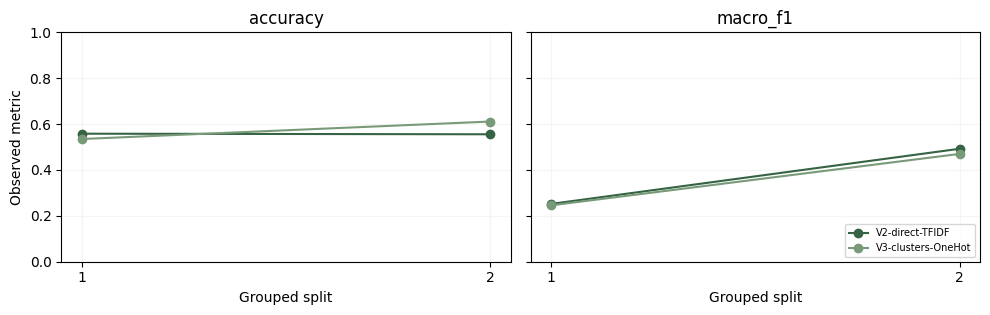

In [15]:
print("Disagreements: V2 direct TF-IDF",int((tfidf_forecast!=y_test.to_numpy()).sum()),
      "| V3 cluster OneHot",int((forecast!=y_test.to_numpy()).sum()))
print("Of V3 disagreements, unseen target classes:",int((~held_out.matches_given_code & ~held_out.class_seen_in_training).sum()))
display(held_out.loc[~held_out.matches_given_code,
                     ["ID","manual_code","tfidf_baseline","cluster_model","class_seen_in_training"]].head(20))

repeated=[]
for run,(tr,te) in enumerate(GroupShuffleSplit(n_splits=2,test_size=.22,random_state=21)
                              .split(X,y,groups=assigned_groups),start=1):
    assert set(assigned_groups.iloc[tr]).isdisjoint(set(assigned_groups.iloc[te]))
    direct=fresh_tfidf_baseline().fit(X.iloc[tr],y.iloc[tr])
    clusters_fold=fresh_cluster_model().fit(X.iloc[tr],y.iloc[tr])
    for representation,trained in [("V2-direct-TFIDF",direct),("V3-clusters-OneHot",clusters_fold)]:
        pred=trained.predict(X.iloc[te]); unseen=~y.iloc[te].isin(set(y.iloc[tr]))
        repeated.append({"split":run,"representation":representation,"n_test":len(te),
                         "unseen_label_rows":int(unseen.sum()),
                         "accuracy":accuracy_score(y.iloc[te],pred),
                         "macro_f1":f1_score(y.iloc[te],pred,average="macro",zero_division=0),
                         "macro_recall":recall_score(y.iloc[te],pred,average="macro",zero_division=0),
                         "weighted_f1":f1_score(y.iloc[te],pred,average="weighted",zero_division=0)})
repeated=pd.DataFrame(repeated)
display(repeated.round(4))
fig,axes=plt.subplots(1,2,figsize=(10.0,3.25),sharey=True)
for ax,metric in zip(axes,["accuracy","macro_f1"]):
    for rep,color in [("V2-direct-TFIDF",PALETTE["blue"]),
                      ("V3-clusters-OneHot",PALETTE["teal"])]:
        d=repeated.loc[repeated.representation.eq(rep)]
        ax.plot(d.split,d[metric],"o-",color=color,label=rep)
    ax.set(title=metric,xlabel="Grouped split",ylim=(0,1),xticks=[1,2])
    ax.grid(alpha=.12)
axes[0].set_ylabel("Observed metric")
axes[1].legend(fontsize=7,loc="lower right")
fig.tight_layout();plt.show()

## 16. הצעות לסימולים חלקיים — בחירה תפעולית מבוקרת
לאחר תום ניסוי הבדיקה, גרסת אשכולות V3 מאומנת מחדש **רק על 191 התוויות המלאות**. לצורכי הדגמה היא מנפקת הצעות לתשעת הקודים החלקיים. ההמלצות נמסרות להכרעת סמלן, והציון `predict_proba` אינו מכויל. **אין להחליף תווית ידנית או לעדכן נתוני מקור באמצעות מיפוי האשכולות.**

מכיוון שמדובר במטלת מיון עם נתוני דמה, הצעות לתוויות חלקיות עדיין מחייבות סקירת סמלן. הייצוג שמפעילים כאן הוא חלופת הייחוס עם `smooth_idf=True`, ולא תוצאה של בחירת פרמטר מהקבוצה החיצונית.


In [16]:
review_model=fresh_cluster_model().fit(X,y)
review_features=model_features(partial)
review_proposed=review_model.predict(review_features)
review_score=review_model.predict_proba(review_features).max(axis=1)
review_queue=pd.DataFrame({"ID":partial["ID"].astype(int).to_numpy(),
                           "partial_source_code":partial[TARGET].astype(str).to_numpy(),
                           "suggested_code":review_proposed,
                           "uncalibrated_score":np.round(review_score,3),
                           "decision":"HUMAN_CODER_REVIEW"})
assert len(review_queue)==9
print("Full-data refit, independent from held-out experiment. All partial-code records:")
display(review_queue)
print("Notebook output tables: performance, clusterer.summary_, all_ch, cluster_members,",
      "programming_examples, held_out, repeated, review_queue")

Full-data refit, independent from held-out experiment. All partial-code records:


,ID,partial_source_code,suggested_code,uncalibrated_score,decision
0,18,1XXX,2511,0.409,HUMAN_CODER_REVIEW
1,45,XXXX,2511,0.200,HUMAN_CODER_REVIEW
2,50,1XXX,2511,0.409,HUMAN_CODER_REVIEW
3,81,1XXX,2511,0.409,HUMAN_CODER_REVIEW
4,108,XXXX,2511,0.200,HUMAN_CODER_REVIEW
5,113,1XXX,2511,0.409,HUMAN_CODER_REVIEW
6,142,XXXX,5223,0.075,HUMAN_CODER_REVIEW
7,165,335X,3354,0.183,HUMAN_CODER_REVIEW
8,193,XXXX,5223,0.587,HUMAN_CODER_REVIEW


Notebook output tables: performance, clusterer.summary_, all_ch, cluster_members, programming_examples, held_out, repeated, review_queue


## 17. פירוק Recall ו-F1 לפי מחלקות משלח היד — בדיקה מהותית
מדווחים על Macro-Recall (ממוצע Recall על המחלקות), Macro-F1 ו-Weighted-F1. חיזוי קוד שלא נצפה כלל באימון הוא בלתי אפשרי למסווג רב-מחלקתי המוגבל למחלקות שנראו בזמן האימון. לכן נציג בנפרד את המדדים של המחלקות שנצפו באימון **מבלי להחליף** את המדדים המלאים. חלוקה זו היא ניתוח שגיאות, לא מדד מבחן חלופי לבחירת מודל.

הבדיקה אינה מספקת הערכה תפעולית של Recall לפי קוד, משום שיש בסימולציה מעט מאוד דוגמאות לכל קוד והרשומות תויגו ידנית עם שיעור שגיאה ידוע רק בקירוב.

In [17]:
from sklearn.metrics import recall_score,precision_score,classification_report

rows=[]
for (branch,smooth),pred in forecast_by_setting.items():
    sub=classification_report(y_test,pred,output_dict=True,zero_division=0)
    per_label=[]
    for code in sorted(set(y_test)):
        actual_n=int(np.sum(y_test.to_numpy()==code))
        code_recall=recall_score(y_test==code,np.asarray(pred)==code,zero_division=0)
        per_label.append({"branch":branch,"smooth_idf":smooth,"occupation_code":code,
                          "support":actual_n,"seen_in_training":code in set(y_train),
                          "recall":code_recall})
    rows.extend(per_label)
class_recall=pd.DataFrame(rows)
print("Per-class recall, actual labels in holdout (all configurations):")
display(class_recall.sort_values(["occupation_code","branch","smooth_idf"]).reset_index(drop=True))

# Aggregate by seen/unseen support. Unseen-class recall is exactly zero for all fitted models.
seen_counts=class_recall.groupby(["branch","smooth_idf","seen_in_training"]).agg(
    n_classes=("occupation_code","nunique"),n_test_records=("support","sum"),
    macro_recall=("recall","mean")
).reset_index()
print("Recall by whether the target code appeared in training:")
display(seen_counts.round(4))
assert (class_recall.loc[~class_recall.seen_in_training,"recall"]==0).all()
print("In single-label multiclass classification, weighted recall equals accuracy,"
      "so both should not be presented as independent evidence.")

Per-class recall, actual labels in holdout (all configurations):


,branch,smooth_idf,occupation_code,support,seen_in_training,recall
0,clusters,False,1212,1,False,0.0
1,clusters,True,1212,1,False,0.0
2,direct,False,1212,1,False,0.0
3,direct,True,1212,1,False,0.0
4,clusters,False,2330,1,False,0.0
...,...,...,...,...,...,...
87,direct,True,9112,4,True,1.0
88,clusters,False,9211,1,True,1.0
89,clusters,True,9211,1,True,1.0
90,direct,False,9211,1,True,1.0


Recall by whether the target code appeared in training:


,branch,smooth_idf,seen_in_training,n_classes,n_test_records,macro_recall
0,clusters,False,False,7,8,0.0000
1,clusters,False,True,16,34,0.9375
2,clusters,True,False,7,8,0.0000
3,clusters,True,True,16,34,0.8542
4,direct,False,False,7,8,0.0000
5,direct,False,True,16,34,0.8750
6,direct,True,False,7,8,0.0000
7,direct,True,True,16,34,0.8750


In single-label multiclass classification, weighted recall equals accuracy,so both should not be presented as independent evidence.


## 18. מסקנות מבחן המיון והגבלות
**מה נבדק והודגם:** בדיקת 18 עמודות מתוך Metadata; בחירת מדיניות תכונות נפרדת מחוזה המקור; סינון תוויות יעד חלקיות; חלוקה מופרדת קבוצות; חיפוש מלא בתוך טווח K המתוקצב עבור כל שדה טקסט; בחירת K לפי Calinski–Harabasz עם שוויון לאחר עיגול ורזולוציה מותאמת; קידוד נומינלי של מזהי האשכולות ב-OneHotEncoder; השוואה ישירה למודל TF-IDF המקורי; בדיקת תוכן ידנית לדוגמאות תכנות; ובניית תור סקירה אנושית.

**מה לא הוכח:** CH גבוה אינו הוכחת שקילות סמנטית, אינו הבטחה לשיפור דיוק סיווג ואינו מבחן F מובהקות. אשכולות מחושבים על מרחקים של TF-IDF תווי, לא על embedding סמנטי. הנתונים הם סימולציה עם תוויות שעלולות להיות שגויות. לא קיימים מזהי משתתף לאורך שידורים, חותמות זמן שידור או קודי אמת שעברו adjudication מקצועי. הגבלת K ל-20 היא החלטת עלות חישוב לצורך מטלה זו, לא טענה לאופטימליות מוחלטת.

**המשך הטמעה:** איסוף מזהה משתתף וגרסה, מדגם תיוג איכותי ועצמאי, אימות לפי משתתף וזמן, בדיקת חוקיות/הומוגניות מקצועית של קבוצות הטקסט עם סמלנים, כיול והימנעות, ומערכת המלצה עם משוב וערבות בקרת נתונים. אין להחליט על הטמעה על בסיס השוואת holdout קטנה יחידה.

**מקורות scikit-learn:** [Calinski–Harabasz](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html) · [Clustering guide](https://scikit-learn.org/stable/modules/clustering.html#calinski-harabasz-index) · [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) · [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) · [Pipeline and leakage](https://scikit-learn.org/stable/common_pitfalls.html) · [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).

**עיצוב:** צבעי הגרפים נבחרו בהשראת התצוגה השמורה של אתר הפורטפוליו. הגרפים עצמם הם חישוב מהנתונים, ולא הדמיה של נתוני אמת חיצוניים.

**הרצה:** המחברת נטענת באופן ציבורי מ-GitHub, מאמתת checksum של קובץ המקור, ומשתמשת בחבילות scikit-learn סטנדרטיות. בדיקת הרצה מקומית אינה הוכחת ביצוע על סביבת Colab בפועל.

**ניסוי רגישות TF-IDF:** `norm="l2"` הוגדר והאימות בוצע על הווקטורים עצמם. שתי חלופות `smooth_idf` נבדקו בלי לשנות את חלוקת הנתונים. נבדקו Macro-F1, Macro-Recall, Weighted-F1 ו-Accuracy וכן Recall לפי קוד, והוצג במפורש שזהו ניסוי השוואתי על holdout ולא תהליך בחירה מאומת של פרמטרי ייצור. תיאורים בעלי דמיון קוסינוס גבוה אינם בהכרח אותו מקצוע.

מקור מתודולוגי נוסף: [TF-IDF norm ו-smooth_idf](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
